## B1. Deskripsi Dataset
Dataset **`titanic`** dari library Seaborn merekam data penumpang kapal Titanic.
- **Jumlah Baris & Kolom:** Lebih dari 800 baris dengan berbagai atribut penumpang.
- **Fitur yang Digunakan:** `pclass` (kelas tiket), `sex` (jenis kelamin), `age` (usia), `fare` (tarif tiket), dan `embarked` (pelabuhan keberangkatan).
- **Variabel Target:** `survived` (kategorikal biner: 0 untuk tidak selamat, 1 untuk selamat).


Statistik Deskriptif:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/tmp/ipykernel_2696/67600654.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_titanic, x='survived', palette='Set2')


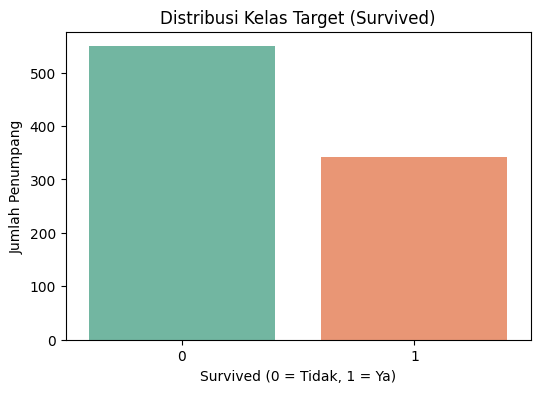

/tmp/ipykernel_2696/67600654.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_titanic, x='survived', y='fare', palette='Set2')


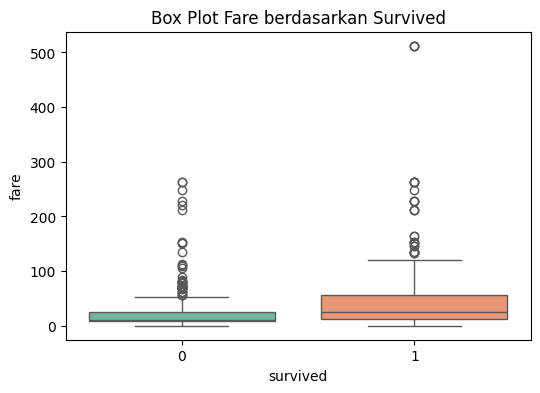

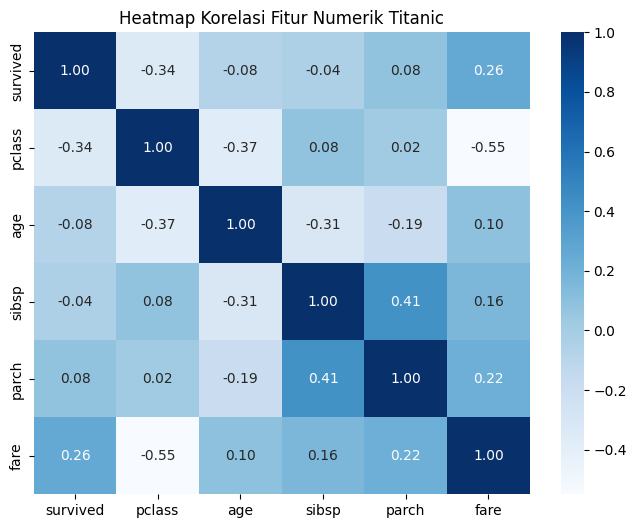

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Memuat dataset titanic
df_titanic = sns.load_dataset('titanic')

# Statistik deskriptif
print("Statistik Deskriptif:")
display(df_titanic.describe(include='all'))

# Visualisasi 1: Bar chart distribusi kelas target (survived)
plt.figure(figsize=(6, 4))
sns.countplot(data=df_titanic, x='survived', palette='Set2')
plt.title('Distribusi Kelas Target (Survived)')
plt.xlabel('Survived (0 = Tidak, 1 = Ya)')
plt.ylabel('Jumlah Penumpang')
plt.show()

# Visualisasi 2: Box plot fitur numerik (fare) per kelas target
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_titanic, x='survived', y='fare', palette='Set2')
plt.title('Box Plot Fare berdasarkan Survived')
plt.show()

# Visualisasi 3: Heatmap korelasi fitur numerik
plt.figure(figsize=(8, 6))
sns.heatmap(df_titanic.select_dtypes(include=[np.number]).corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Heatmap Korelasi Fitur Numerik Titanic')
plt.show()


## Temuan dari Visualisasi:
1. **Bar Chart Target (`survived`):** Menunjukkan jumlah penumpang yang tidak selamat lebih banyak dibanding yang selamat (sedikit tidak seimbang, sehingga penanganan kelas penting).
2. **Box Plot (`fare` vs `survived`):** Penumpang yang membayar tarif (*fare*) lebih tinggi cenderung memiliki peluang keselamatan yang lebih besar.
3. **Heatmap Korelasi:** Menunjukkan hubungan antara fitur numerik seperti `fare`, `pclass`, dan `age` terhadap status keselamatan.


In [ ]:
from sklearn.model_selection import train_test_split

# B3 & B4. Preprocessing & Pembersihan Data (Menghapus missing values pada baris terpilih)
df_titanic_clean = df_titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked']].dropna()

X = df_titanic_clean[['pclass', 'sex', 'age', 'fare', 'embarked']]
y = df_titanic_clean['survived']

# B5. Pembagian Data dengan stratify agar proporsi kelas terjaga
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Ukuran Data Latih:", X_train.shape)
print("Ukuran Data Uji:", X_test.shape)

Ukuran Data Latih: (569, 5)
Ukuran Data Uji: (143, 5)


Accuracy: 0.7832167832167832
Precision: 0.6956521739130435
Recall: 0.8275862068965517
F1-Score: 0.7559055118110236
ROC-AUC: 0.8453346855983773


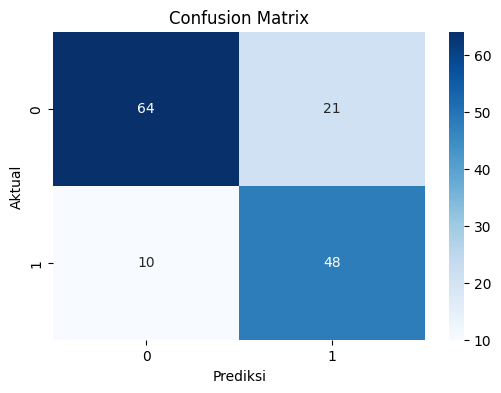

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve

# Preprocessing Pipeline untuk numerik dan kategorikal
numeric_features = ['age', 'fare']
categorical_features = ['pclass', 'sex', 'embarked']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ]
)

# B6. Membangun model Logistic Regression dengan class_weight='balanced'
model_logreg = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', random_state=42))
])

# Pelatihan Model
model_logreg.fit(X_train, y_train)

# Prediksi
y_pred = model_logreg.predict(X_test)
y_prob = model_logreg.predict_proba(X_test)[:, 1]

# B7. Evaluasi Metrik
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()
